##NMOS CHARACTERIZATION ##


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load ngspice data
df = pd.read_csv(
    "/content/nmos_transfer.dat",
    sep=r"\s+",
    comment="*"
)

# Select gate voltage and drain current
vgs = df["v(g)"].to_numpy()
id_n = np.abs(df["id_n"].to_numpy())

# Sort by gate voltage
order = np.argsort(vgs)
vgs = vgs[order]
id_n = id_n[order]

# Transconductance: gm = dId/dVgs
gm = np.gradient(id_n, vgs)

# Current efficiency: gm/Id
gm_id = np.divide(
    gm,
    id_n,
    out=np.full_like(gm, np.nan),
    where=id_n > 1e-12
)


FileNotFoundError: [Errno 2] No such file or directory: '/content/nmos_transfer.dat'

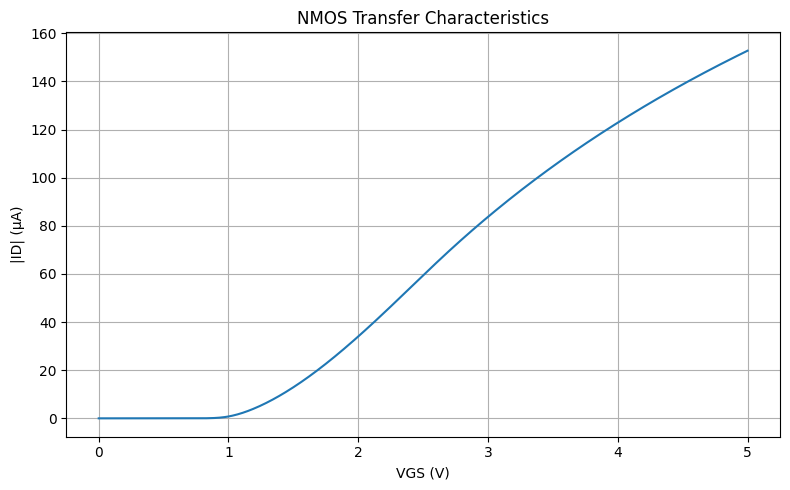

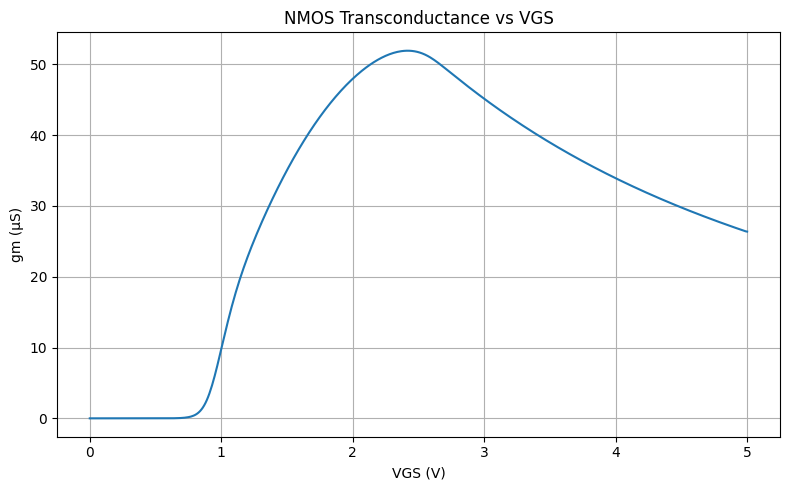

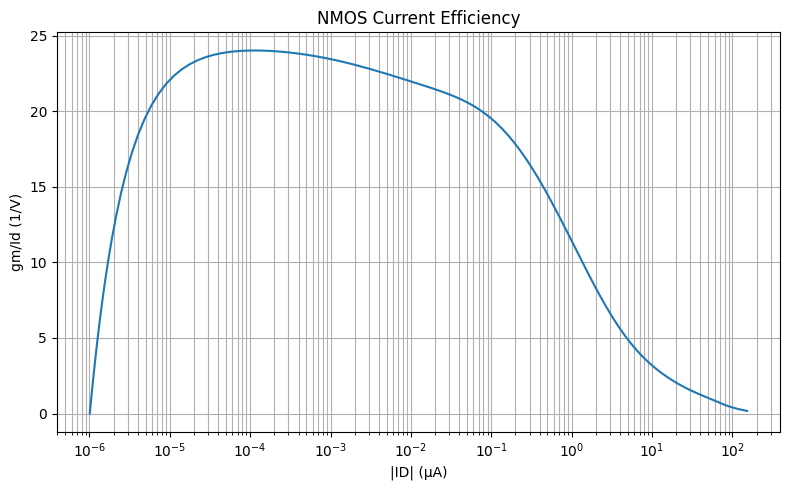

Number of data points: 501
Maximum simulated current (µA): 152.777668
Maximum numerical gm (µS): 51.92208499999991


In [ ]:

# Plot 1: Id vs Vgs
plt.figure(figsize=(8, 5))
plt.plot(vgs, id_n * 1e6)
plt.xlabel("VGS (V)")
plt.ylabel("|ID| (µA)")
plt.title("NMOS Transfer Characteristics")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 2: gm vs Vgs
plt.figure(figsize=(8, 5))
plt.plot(vgs, gm * 1e6)
plt.xlabel("VGS (V)")
plt.ylabel("gm (µS)")
plt.title("NMOS Transconductance vs VGS")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 3: gm/Id vs Id
valid = (id_n > 1e-12) & (gm > 0)

plt.figure(figsize=(8, 5))
plt.semilogx(id_n[valid] * 1e6, gm_id[valid])
plt.xlabel("|ID| (µA)")
plt.ylabel("gm/Id (1/V)")
plt.title("NMOS Current Efficiency")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

print("Number of data points:", len(vgs))
print("Maximum simulated current (µA):", id_n.max() * 1e6)
print("Maximum numerical gm (µS):", gm.max() * 1e6)


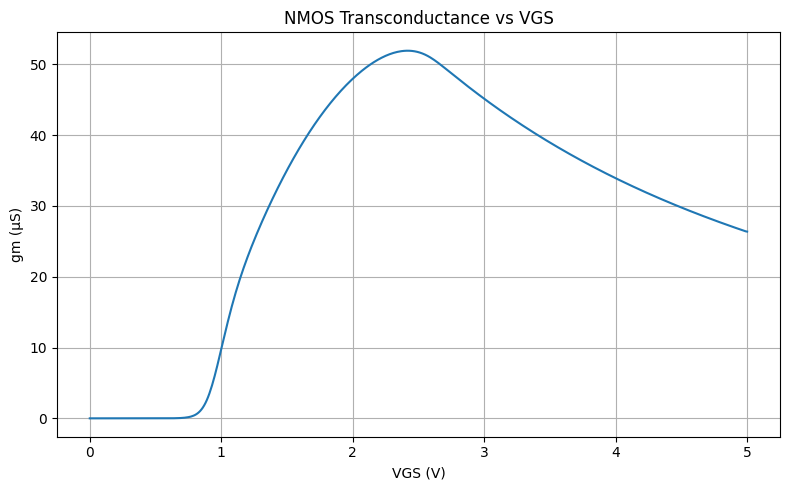

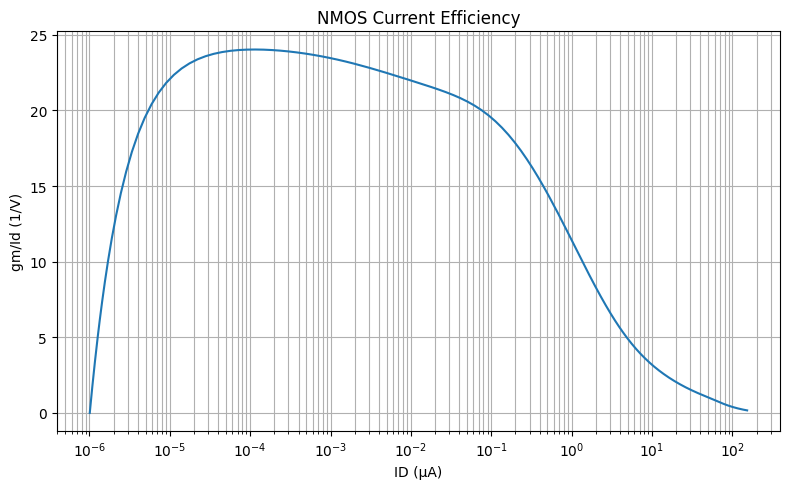

Maximum gm: 51.92 µS
Maximum ID: 152.78 µA


In [ ]:

# Plot 1: gm vs VGS
plt.figure(figsize=(8, 5))
plt.plot(vgs, gm * 1e6)
plt.xlabel("VGS (V)")
plt.ylabel("gm (µS)")
plt.title("NMOS Transconductance vs VGS")
plt.grid(True)
plt.tight_layout()
plt.show()

# Plot 2: gm/Id vs Id
valid = (id_n > 1e-12) & (gm > 0)

plt.figure(figsize=(8, 5))
plt.semilogx(id_n[valid] * 1e6, gm_id[valid])
plt.xlabel("ID (µA)")
plt.ylabel("gm/Id (1/V)")
plt.title("NMOS Current Efficiency")
plt.grid(True, which="both")
plt.tight_layout()
plt.show()

# Print useful operating-point information
print(f"Maximum gm: {np.max(gm) * 1e6:.2f} µS")
print(f"Maximum ID: {np.max(id_n) * 1e6:.2f} µA")


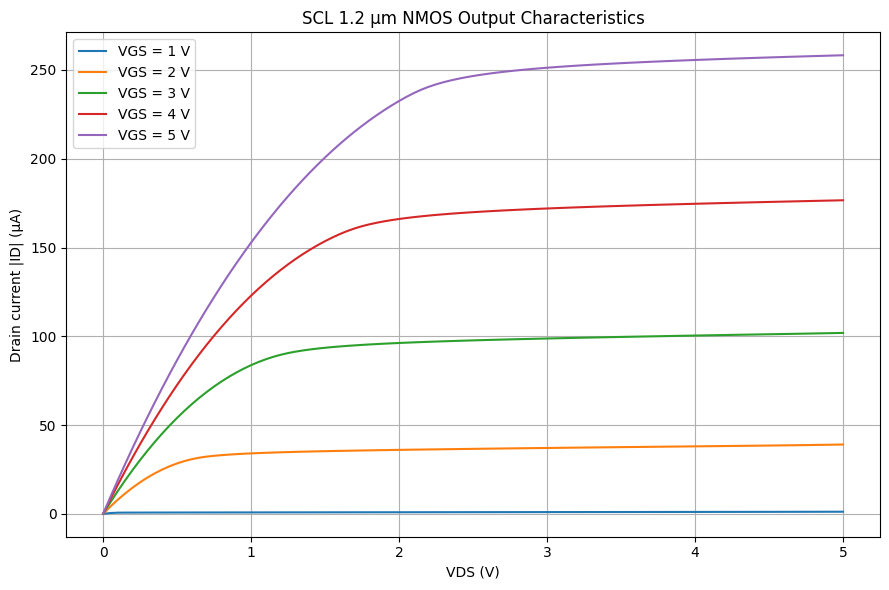

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for vgs in range(1, 6):
    filename = f"nmos_output_vgs{vgs}.dat"
    data = np.loadtxt(filename, skiprows=1)

    vds = data[:, 0]
    ids = np.abs(data[:, -1]) * 1e6

    plt.plot(vds, ids, label=f"VGS = {vgs} V")

plt.xlabel("VDS (V)")
plt.ylabel("Drain current |ID| (µA)")
plt.title("SCL 1.2 µm NMOS Output Characteristics")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("nmos_output_characteristics.png", dpi=300)
plt.show()

# PMOS


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt('/content/pmos_gm_id_data.txt')

V = data[:, 0]
Id = np.abs(data[:, 2])
col4 = data[:, 3]
col5 = data[:, 4]

print("Data shape:", data.shape)
print("Voltage range:", V.min(), "to", V.max(), "V")
print("Current range:", Id.min(), "to", Id.max(), "A")



Data shape: (501, 5)
Voltage range: 0.0 to 5.0 V
Current range: 1.0099907e-12 to 9.59014531e-05 A


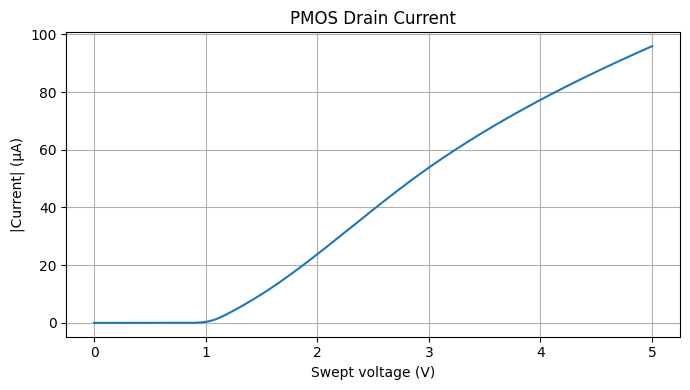

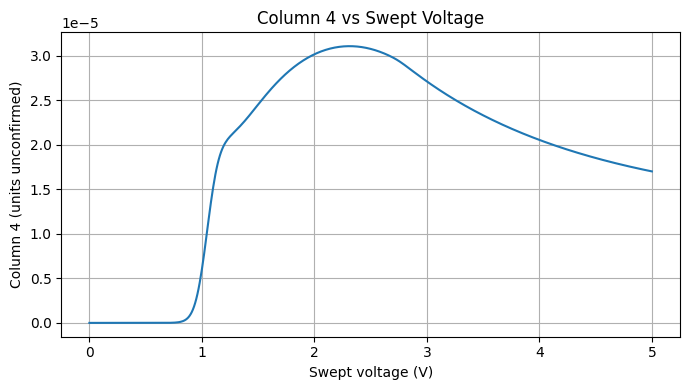

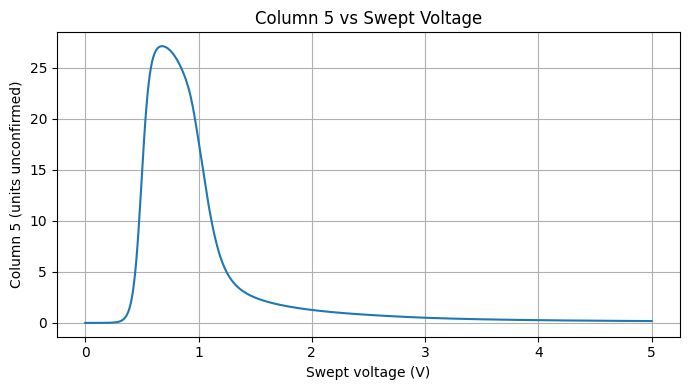

In [ ]:
# 1. Drain current
plt.figure(figsize=(7, 4))
plt.plot(V, Id * 1e6)
plt.xlabel('Swept voltage (V)')
plt.ylabel('|Current| (µA)')
plt.title('PMOS Drain Current')
plt.grid(True)
plt.tight_layout()
plt.show()

# 2. Fourth column
plt.figure(figsize=(7, 4))
plt.plot(V, col4)
plt.xlabel('Swept voltage (V)')
plt.ylabel('Column 4 (units unconfirmed)')
plt.title('Column 4 vs Swept Voltage')
plt.grid(True)
plt.tight_layout()
plt.show()

# 3. Fifth column
plt.figure(figsize=(7, 4))
plt.plot(V, col5)
plt.xlabel('Swept voltage (V)')
plt.ylabel('Column 5 (units unconfirmed)')
plt.title('Column 5 vs Swept Voltage')
plt.grid(True)
plt.tight_layout()
plt.show()

Peak gm = 31.0700 µS
At swept voltage = 2.31 V
Drain current = 33.3257 µA
gm/Id = 0.9323 V^-1


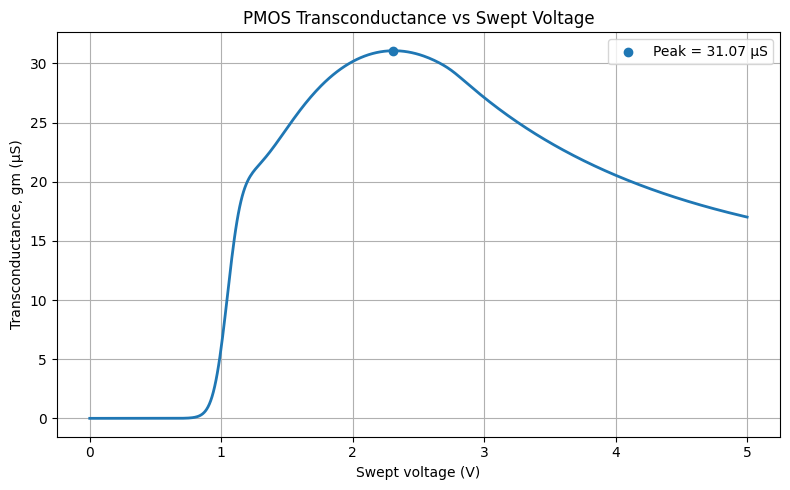

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt('/content/pmos_gm_id_data.txt')

V = data[:, 0]
Id = np.abs(data[:, 2])
gm_id = data[:, 4]

# Calculate gm from gm/Id and drain current
gm = gm_id * Id

# Find peak gm
i_peak = np.argmax(gm)

print(f"Peak gm = {gm[i_peak]*1e6:.4f} µS")
print(f"At swept voltage = {V[i_peak]:.2f} V")
print(f"Drain current = {Id[i_peak]*1e6:.4f} µA")
print(f"gm/Id = {gm_id[i_peak]:.4f} V^-1")

# Plot gm
plt.figure(figsize=(8, 5))
plt.plot(V, gm * 1e6, linewidth=2)
plt.scatter(V[i_peak], gm[i_peak] * 1e6, zorder=3,
            label=f'Peak = {gm[i_peak]*1e6:.2f} µS')
plt.xlabel('Swept voltage (V)')
plt.ylabel('Transconductance, gm (µS)')
plt.title('PMOS Transconductance vs Swept Voltage')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

TX-2.5V 30_40_50_60
